# 02 · Diagnóstico espacial

**Por qué este notebook.** En la presentación de avance los profesores pidieron *considerar bien la correlación espacial*. Antes de modelar hay que medir:

1. **Cuánto se parecen las celdas vecinas** (I de Moran global).
2. **Hasta qué distancia llega ese parecido** (correlograma). Esa distancia define el tamaño de los bloques de la validación cruzada espacial.
3. **Dónde se agrupan los supermercados** (LISA o Moran local).
4. **Si la población del entorno explica más que la de la celda** (Spearman). Eso justifica las variables de entorno de `03_filtro_y_entorno.ipynb`.

**Datos.** Grilla de 250 m (`celdas_<ciudad>_250m.parquet` y `modelo_250m.parquet`). Se usan dos universos de celdas:

| Universo | Qué celdas | Para qué |
| --- | --- | --- |
| **Habitables** (principal) | A 750 m o menos de una celda poblada (filtro X de la sección 5.4 del README). Es el universo del modelo | Conclusiones y bloques de validación |
| **Activas** | Con población o con algún supermercado, paradero o punto de interés | Comparar con la primera prueba del plan |

**Vecindad.** Pesos por distancia entre centros de celda, binarios y estandarizados por fila. A 360 m cada celda tiene como vecinas las 8 que la rodean (la diagonal mide 354 m).

No necesita los datos crudos: lee solo `data/processed/`. Corre en menos de dos minutos.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import sparse
from scipy.spatial import cKDTree
from scipy.stats import spearmanr
import libpysal
import esda

RAIZ = Path(".")
PROC = RAIZ / "data" / "processed"
SALIDA = RAIZ / "resultados" / "diagnostico_espacial"
SALIDA.mkdir(parents=True, exist_ok=True)

SEMILLA = 42
PERMUTACIONES = 999
UMBRAL_VECINAS = 360                     # las 8 celdas que rodean a cada una
DISTANCIAS = [360, 500, 1000, 2000, 3000, 5000]
CIUDADES = {"stgo": "Gran Santiago", "ccp": "Gran Concepción"}
VARIABLES = {"n_supermercados": "Supermercados", "poblacion_celda": "Población"}

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

## Datos y universos de celdas

In [2]:
modelo = pd.read_parquet(PROC / "modelo_250m.parquet")

universos = {}
for c in CIUDADES:
    t = pd.read_parquet(PROC / f"celdas_{c}_250m.parquet")
    activas = t[(t.poblacion_celda > 0) | (t.n_supermercados > 0)
                | (t.filter(like="conteo_").sum(axis=1) > 0)].reset_index(drop=True)
    habitables = modelo[modelo.ciudad == c].reset_index(drop=True)
    universos[(c, "habitables")] = habitables
    universos[(c, "activas")] = activas

resumen = pd.DataFrame([
    {"ciudad": CIUDADES[c], "universo": u, "celdas": len(d),
     "supermercados": int(d.n_supermercados.sum()),
     "celdas con supermercado": int((d.n_supermercados > 0).sum()),
     "% celdas con supermercado": 100 * (d.n_supermercados > 0).mean(),
     "habitantes": int(d.poblacion_celda.sum())}
    for (c, u), d in universos.items()])
resumen

,ciudad,universo,celdas,supermercados,celdas con supermercado,% celdas con supermercado,habitantes
0,Gran Santiago,habitables,19128,520,486,2.541,6532737
1,Gran Santiago,activas,11067,524,490,4.428,6532737
2,Gran Concepción,habitables,5820,159,138,2.371,954408
3,Gran Concepción,activas,2662,159,138,5.184,954408


## Funciones

`moran_global` calcula el I de Moran con una matriz de pesos dispersa (`scipy.sparse`). Con vecinos a 5 km cada celda de Santiago tiene más de mil vecinas, y la estructura de `libpysal` se vuelve lenta y pesada en memoria. La fórmula y la prueba por permutaciones son las mismas de `esda.Moran`; la celda siguiente lo comprueba a 360 m.

Además del correlograma **acumulado** (vecinas a *d* metros o menos, como en el plan), se calcula el correlograma **por anillos** (vecinas entre la distancia anterior y *d*). El acumulado siempre arrastra a las vecinas cercanas, así que baja lento; el de anillos muestra directamente a qué distancia dos celdas dejan de parecerse, que es lo que importa para separar los bloques de validación.

In [3]:
def pares_vecinos(xy, d_max, d_min=0.0):
    # Pares (i, j) de celdas con d_min < distancia <= d_max, en ambos sentidos.
    pares = cKDTree(xy).query_pairs(d_max + 1e-6, output_type="ndarray")
    if d_min > 0:
        d = np.hypot(*(xy[pares[:, 0]] - xy[pares[:, 1]]).T)
        pares = pares[d > d_min + 1e-6]
    return np.r_[pares[:, 0], pares[:, 1]], np.r_[pares[:, 1], pares[:, 0]]


def moran_global(y, xy, d_max, d_min=0.0, permutaciones=PERMUTACIONES, semilla=SEMILLA):
    # I de Moran con pesos binarios por distancia, estandarizados por fila.
    # Las celdas sin vecinas (islas) quedan con rezago 0, igual que en esda.
    y = np.asarray(y, dtype=float)
    n = len(y)
    i, j = pares_vecinos(xy, d_max, d_min)
    W = sparse.csr_matrix((np.ones(len(i)), (i, j)), shape=(n, n))
    k = np.asarray(W.sum(axis=1)).ravel()
    W = sparse.diags(np.where(k > 0, 1 / np.maximum(k, 1), 0.0)) @ W
    s0 = (k > 0).sum()
    z = y - y.mean()
    zz = z @ z
    I = n / s0 * (z @ (W @ z)) / zz
    rng = np.random.default_rng(semilla)
    sim = np.array([n / s0 * (zp @ (W @ zp)) / zz
                    for zp in (rng.permutation(z) for _ in range(permutaciones))])
    mayores = (sim >= I).sum()
    mayores = min(mayores, permutaciones - mayores)      # misma regla que esda
    return {"I": I, "p_sim": (mayores + 1) / (permutaciones + 1),
            "z_sim": (I - sim.mean()) / sim.std(), "vecinas_promedio": k.mean(),
            "islas": int((k == 0).sum())}


def pesos_libpysal(xy, umbral):
    w = libpysal.weights.DistanceBand(xy, threshold=umbral, binary=True, silence_warnings=True)
    w.transform = "r"
    return w


# Control: la función dispersa reproduce a esda.Moran a 360 m
d = universos[("stgo", "activas")]
xy = d[["x", "y"]].to_numpy()
np.random.seed(SEMILLA)
ref = esda.Moran(d.n_supermercados.to_numpy(), pesos_libpysal(xy, UMBRAL_VECINAS), permutations=PERMUTACIONES)
mia = moran_global(d.n_supermercados, xy, UMBRAL_VECINAS)
assert np.isclose(ref.I, mia["I"]), (ref.I, mia["I"])
print(f"esda: I = {ref.I:.5f} · función dispersa: I = {mia['I']:.5f}")

esda: I = 0.04893 · función dispersa: I = 0.04893


## b) I de Moran global con las 8 vecinas (360 m)

El I de Moran va de −1 a 1. Cerca de 0 = las celdas vecinas no se parecen más de lo que se parecerían al azar; positivo = valores parecidos se agrupan. El valor *p* sale de 999 permutaciones: se reparten los valores al azar entre las celdas y se cuenta cuántas veces el azar da un I tan extremo como el observado.

In [4]:
filas = []
for (c, u), d in universos.items():
    xy = d[["x", "y"]].to_numpy()
    w = pesos_libpysal(xy, UMBRAL_VECINAS)
    for var, nombre in VARIABLES.items():
        np.random.seed(SEMILLA)
        mi = esda.Moran(d[var].to_numpy().astype(float), w, permutations=PERMUTACIONES)
        filas.append({"ciudad": CIUDADES[c], "universo": u, "variable": nombre,
                      "I": mi.I, "p_sim": mi.p_sim, "z_sim": mi.z_sim,
                      "celdas": len(d), "islas": len(w.islands)})
moran_360 = pd.DataFrame(filas)
moran_360.to_csv(SALIDA / "moran_global_360m.csv", index=False)
moran_360

,ciudad,universo,variable,I,p_sim,z_sim,celdas,islas
0,Gran Santiago,habitables,Supermercados,0.064,0.001,17.527,19128,0
1,Gran Santiago,habitables,Población,0.492,0.001,135.116,19128,0
2,Gran Santiago,activas,Supermercados,0.049,0.001,8.767,11067,220
3,Gran Santiago,activas,Población,0.340,0.001,60.065,11067,220
4,Gran Concepción,habitables,Supermercados,0.101,0.001,14.701,5820,0
5,Gran Concepción,habitables,Población,0.395,0.001,54.694,5820,0
6,Gran Concepción,activas,Supermercados,0.087,0.001,6.763,2662,75
7,Gran Concepción,activas,Población,0.223,0.001,17.433,2662,75


## c) Correlograma: el I de Moran a distintas distancias

In [5]:
filas = []
for (c, u), d in universos.items():
    xy = d[["x", "y"]].to_numpy()
    for var, nombre in VARIABLES.items():
        previa = 0
        for dist in DISTANCIAS:
            acum = moran_global(d[var], xy, dist)
            anillo = acum if previa == 0 else moran_global(d[var], xy, dist, previa)
            for tipo, d_min, r in [("acumulado", 0, acum), ("anillo", previa, anillo)]:
                filas.append({"ciudad": CIUDADES[c], "universo": u, "variable": nombre,
                              "tipo": tipo, "d_min_m": d_min, "d_max_m": dist, **r})
            previa = dist
correlograma = pd.DataFrame(filas)
correlograma.to_csv(SALIDA / "correlograma.csv", index=False)

(correlograma[correlograma.universo == "habitables"]
 .pivot_table(index=["variable", "tipo", "d_max_m"], columns="ciudad", values="I")
 .round(3))

ciudad                           Gran Concepción  Gran Santiago
variable      tipo      d_max_m                                
Población     acumulado 360                0.395          0.492
                        500                0.374          0.476
                        1000               0.271          0.394
                        2000               0.161          0.297
                        3000               0.114          0.250
                        5000               0.078          0.198
              anillo    360                0.395          0.492
                        500                0.331          0.445
                        1000               0.233          0.366
                        2000               0.118          0.264
                        3000               0.053          0.210
                        5000               0.034          0.169
Supermercados acumulado 360                0.101          0.064
                        500                0.089          0.056
                        1000               0.053          0.043
                        2000               0.025          0.034
                        3000               0.015          0.028
                        5000               0.011          0.020
              anillo    360                0.101          0.064
                        500                0.066          0.042
                        1000               0.040          0.039
                        2000               0.014          0.031
                        3000               0.004          0.023
                        5000               0.008          0.016

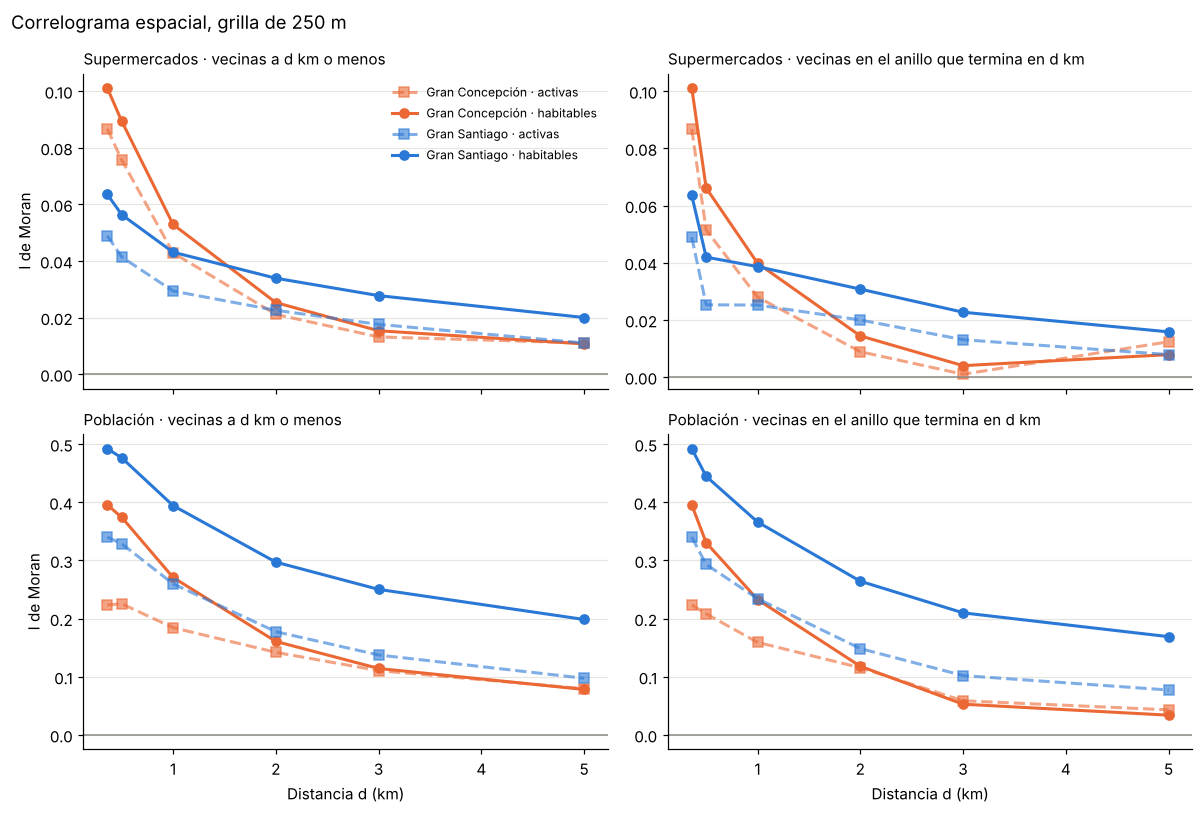

In [6]:
COLOR_CIUDAD = {"Gran Santiago": "#2a78d6", "Gran Concepción": "#eb6834"}
ESTILO_UNIVERSO = {"habitables": dict(ls="-", marker="o"), "activas": dict(ls="--", marker="s", alpha=0.6)}

fig, ejes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True)
for f, (var, nombre) in enumerate(VARIABLES.items()):
    for col, tipo in enumerate(["acumulado", "anillo"]):
        ax = ejes[f, col]
        sel = correlograma[(correlograma.variable == nombre) & (correlograma.tipo == tipo)]
        for (ciudad, u), g in sel.groupby(["ciudad", "universo"]):
            g = g.sort_values("d_max_m")
            ax.plot(g.d_max_m / 1000, g.I, color=COLOR_CIUDAD[ciudad], lw=2, ms=6,
                    label=f"{ciudad} · {u}", **ESTILO_UNIVERSO[u])
        ax.axhline(0, color="#8a8984", lw=1)
        ax.grid(axis="y", color="#e6e5e0", lw=0.8)
        titulo = "vecinas a d km o menos" if tipo == "acumulado" else "vecinas en el anillo que termina en d km"
        ax.set_title(f"{nombre} · {titulo}", loc="left", fontsize=10)
        if f == 1:
            ax.set_xlabel("Distancia d (km)")
        if col == 0:
            ax.set_ylabel("I de Moran")
ejes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle("Correlograma espacial, grilla de 250 m", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(SALIDA / "correlograma.png", bbox_inches="tight")
plt.show()

## d) LISA: dónde se agrupan los supermercados

El Moran local compara cada celda con sus 8 vecinas y la clasifica en un cuadrante:

| Cluster | Significa |
| --- | --- |
| **Alto-alto** | Celda con supermercado rodeada de vecinas con supermercados: polo comercial |
| Alto-bajo | Supermercado aislado: vecinas sin supermercados |
| Bajo-alto | Celda sin supermercado al lado de vecinas con supermercados |
| Bajo-bajo | Celda sin supermercado en zona sin supermercados (la gran mayoría, porque casi todas las celdas tienen 0) |

Solo se pintan las celdas con *p* < 0,05 en 999 permutaciones. Ojo: son miles de pruebas a la vez y con 999 permutaciones el *p* mínimo es 0,001, que no alcanza para pasar un control de falsos descubrimientos (FDR) con 19 mil celdas. Por eso los alto-alto se leen como **zonas candidatas a polo comercial**, no como prueba formal celda por celda.

**Corrección de empates.** Con casi todas las celdas en 0, muchas permutaciones dan *exactamente* el mismo I local que el observado (por ejemplo, una celda sin supermercado con 8 vecinas en 0 da el mismo valor en el 80% de las permutaciones). `esda` compara con `>=` en punto flotante y esos empates a veces quedan como "menores" por diferencias en el último decimal, así que el *p* sale 0,001 cuando en realidad es cercano a 0,2. Por eso el *p* se recalcula a partir de las simulaciones (`lisa.rlisas`) contando los empates con una tolerancia. Sin esta corrección, el 66% de las celdas habitables de Santiago aparece como "bajo-bajo" significativo.

In [7]:
NOMBRE_CLUSTER = {0: "No significativo", 1: "Alto-alto", 2: "Bajo-alto", 3: "Bajo-bajo", 4: "Alto-bajo"}
COLOR_CLUSTER = {0: "#e6e5e0", 1: "#e34948", 2: "#9cc3ee", 3: "#2a78d6", 4: "#eda100"}

def p_con_empates(lisa, tol=1e-9):
    # p de permutación de dos colas plegadas (como esda), contando los empates como "tan extremos".
    sim, obs = lisa.rlisas, lisa.Is[:, None]
    margen = tol * np.maximum(1.0, np.abs(obs))
    mayores = (sim >= obs - margen).sum(axis=1)
    menores = (sim <= obs + margen).sum(axis=1)
    return (np.minimum(mayores, menores) + 1) / (sim.shape[1] + 1)


lisas, filas = {}, []
for (c, u), d in universos.items():
    xy = d[["x", "y"]].to_numpy()
    lisa = esda.Moran_Local(d.n_supermercados.to_numpy().astype(float), pesos_libpysal(xy, UMBRAL_VECINAS),
                            permutations=PERMUTACIONES, seed=SEMILLA)
    p = p_con_empates(lisa)
    cluster = np.where(p < 0.05, lisa.q, 0)
    out = d[["id_celda", "x", "y", "n_supermercados", "poblacion_celda"]].copy()
    out["cluster"], out["p_sim"], out["p_sim_esda"] = cluster, p, lisa.p_sim
    lisas[(c, u)] = out
    for q, nombre in NOMBRE_CLUSTER.items():
        sel = out.cluster == q
        filas.append({"ciudad": CIUDADES[c], "universo": u, "cluster": nombre, "celdas": int(sel.sum()),
                      "supermercados": int(out.loc[sel, "n_supermercados"].sum()),
                      "celdas sin corregir empates": int(((lisa.p_sim < 0.05) & (lisa.q == q)).sum()) if q
                      else int((lisa.p_sim >= 0.05).sum())})
lisa_resumen = pd.DataFrame(filas)
lisa_resumen.to_csv(SALIDA / "lisa_resumen.csv", index=False)
pd.concat([v.assign(universo=k[1]) for k, v in lisas.items()]).to_parquet(SALIDA / "lisa_celdas_250m.parquet", index=False)
lisa_resumen[lisa_resumen.universo == "habitables"]

/usr/local/lib/python3.13/site-packages/esda/moran.py:1398: RuntimeWarning: invalid value encountered in divide
  self.z_sim = (self.Is - self.EI_sim) / self.seI_sim


/usr/local/lib/python3.13/site-packages/esda/moran.py:1398: RuntimeWarning: invalid value encountered in divide
  self.z_sim = (self.Is - self.EI_sim) / self.seI_sim


,ciudad,universo,cluster,celdas,supermercados,celdas sin corregir empates
0,Gran Santiago,habitables,No significativo,18378,434,3101
1,Gran Santiago,habitables,Alto-alto,78,86,217
2,Gran Santiago,habitables,Bajo-alto,672,0,2871
3,Gran Santiago,habitables,Bajo-bajo,0,0,12674
4,Gran Santiago,habitables,Alto-bajo,0,0,265
10,Gran Concepción,habitables,No significativo,5514,111,391
11,Gran Concepción,habitables,Alto-alto,40,48,40
12,Gran Concepción,habitables,Bajo-alto,266,0,387
13,Gran Concepción,habitables,Bajo-bajo,0,0,5000
14,Gran Concepción,habitables,Alto-bajo,0,0,2


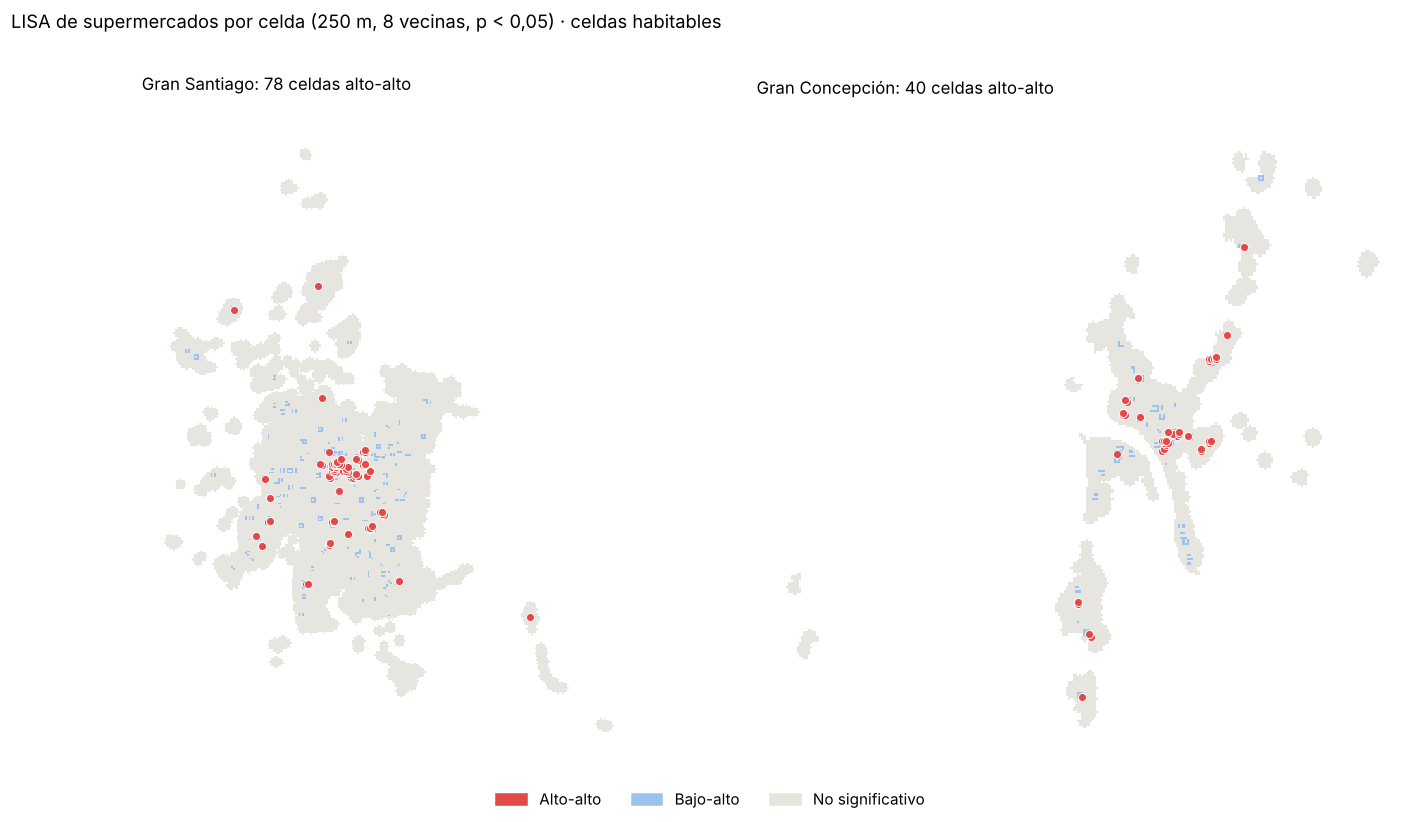

In [8]:
def cuadrados(df, crs, lado=250):
    h = lado / 2
    geom = gpd.GeoSeries.from_xy(df.x, df.y, crs=crs).buffer(h, cap_style="square")
    return gpd.GeoDataFrame(df, geometry=geom, crs=crs)

fig, ejes = plt.subplots(1, 2, figsize=(13, 7.5), gridspec_kw={"width_ratios": [1.15, 1]})
for ax, c in zip(ejes, CIUDADES):
    out = lisas[(c, "habitables")]
    crs = modelo.loc[modelo.ciudad == c, "crs_utm"].iloc[0]
    g = cuadrados(out, crs)
    g[g.cluster == 0].plot(ax=ax, color=COLOR_CLUSTER[0], linewidth=0)
    for q in [3, 2, 4]:
        if (g.cluster == q).any():
            g[g.cluster == q].plot(ax=ax, color=COLOR_CLUSTER[q], linewidth=0)
    hh = out[out.cluster == 1]
    # Las celdas de 250 m casi no se ven a escala de ciudad: los alto-alto se marcan con un punto
    ax.scatter(hh.x, hh.y, s=28, color=COLOR_CLUSTER[1], edgecolor="white", linewidth=0.6, zorder=3)
    ax.set_title(f"{CIUDADES[c]}: {int((out.cluster == 1).sum())} celdas alto-alto", loc="left", fontsize=11)
    ax.set_axis_off()
    ax.set_aspect("equal")

conteo = lisa_resumen[lisa_resumen.universo == "habitables"].groupby("cluster").celdas.sum()
presentes = [q for q in [1, 4, 2, 3, 0] if conteo.get(NOMBRE_CLUSTER[q], 0) > 0]   # solo los que aparecen
leyenda = [Patch(color=COLOR_CLUSTER[q], label=NOMBRE_CLUSTER[q]) for q in presentes]
fig.legend(handles=leyenda, loc="lower center", ncol=len(leyenda), frameon=False)
fig.suptitle("LISA de supermercados por celda (250 m, 8 vecinas, p < 0,05) · celdas habitables",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout(rect=(0, 0.05, 1, 0.97))
fig.savefig(SALIDA / "lisa_supermercados_250m.png", bbox_inches="tight")
plt.show()

## e) Población de la celda vs. población del entorno

Correlación de Spearman entre `n_supermercados` y:

- `poblacion_celda`: habitantes de la propia celda.
- **Rezago espacial a 1 km**: habitantes de las celdas a 1 km o menos, **sin contar la propia celda** (`libpysal.weights.lag_spatial` con pesos binarios).

Si la correlación sube al mirar el entorno, la demanda de un supermercado está en el área que lo rodea y no solo en su celda.

In [9]:
filas = []
for (c, u), d in universos.items():
    xy = d[["x", "y"]].to_numpy()
    w1 = libpysal.weights.DistanceBand(xy, threshold=1000, binary=True, silence_warnings=True)
    rezago = libpysal.weights.lag_spatial(w1, d.poblacion_celda.to_numpy())
    for nombre, x in [("población de la celda", d.poblacion_celda), ("población a 1 km (sin la celda)", rezago)]:
        rho, p = spearmanr(d.n_supermercados, x)
        filas.append({"ciudad": CIUDADES[c], "universo": u, "variable": nombre, "rho": rho, "p": p})
spearman = pd.DataFrame(filas)
spearman.to_csv(SALIDA / "spearman_poblacion.csv", index=False)
spearman.pivot_table(index=["ciudad", "universo"], columns="variable", values="rho", sort=False).round(3)

variable                    población de la celda  \
ciudad          universo                            
Gran Santiago   habitables                  0.118   
                activas                     0.020   
Gran Concepción habitables                  0.144   
                activas                     0.011   

variable                    población a 1 km (sin la celda)  
ciudad          universo                                     
Gran Santiago   habitables                            0.152  
                activas                               0.097  
Gran Concepción habitables                            0.168  
                activas                               0.128

## ¿Cuántos bloques quedan para la validación?

Si los bloques de la validación cruzada espacial son cuadrados de lado *L*, cuántos tienen celdas habitables y cuántos tienen al menos un supermercado. Con muy pocos bloques por ciudad la validación queda inestable.

In [10]:
filas = []
for c in CIUDADES:
    d = universos[(c, "habitables")]
    for lado in [1000, 2000, 3000, 5000]:
        bloque = (d.x // lado).astype(int).astype(str) + "_" + (d.y // lado).astype(int).astype(str)
        sup = d.groupby(bloque).n_supermercados.sum()
        filas.append({"ciudad": CIUDADES[c], "lado_bloque_m": lado, "bloques": sup.size,
                      "bloques con supermercado": int((sup > 0).sum()),
                      "celdas por bloque (mediana)": float(bloque.value_counts().median())})
bloques = pd.DataFrame(filas)
bloques.to_csv(SALIDA / "bloques_validacion.csv", index=False)
bloques.pivot_table(index="lado_bloque_m", columns="ciudad",
                    values=["bloques", "bloques con supermercado"], sort=False)

bloques                 bloques con supermercado  \
ciudad        Gran Santiago Gran Concepción            Gran Santiago   
lado_bloque_m                                                          
1000              1,489.000         544.000                  327.000   
2000                462.000         192.000                  168.000   
3000                230.000         106.000                   98.000   
5000                101.000          59.000                   53.000   

                               
ciudad        Gran Concepción  
lado_bloque_m                  
1000                   80.000  
2000                   45.000  
3000                   33.000  
5000                   23.000

## Conclusiones

Cifras en las celdas habitables de 250 m (el universo del modelo). Las tablas completas están en `resultados/diagnostico_espacial/`.

1. **Hay correlación espacial, pero es débil en los supermercados y fuerte en la población.** Con las 8 vecinas, el I de Moran de `n_supermercados` es 0,06 en Santiago y 0,10 en Concepción (p = 0,001 en ambas); el de la población es 0,49 y 0,40. El valor bajo de los supermercados se explica en parte porque el 97,5% de las celdas tiene 0: el I de Moran sobre conteos tan escasos queda bajo aunque los supermercados sí se agrupen.
2. **El parecido entre celdas se apaga entre 2 y 3 km.** En el correlograma por anillos, el I de los supermercados en Concepción baja a 0,004 en el anillo de 2 a 3 km. En Santiago baja más lento (0,023 en ese anillo y 0,016 entre 3 y 5 km), y la población mantiene 0,17 a 5 km por el gradiente centro-periferia de toda la ciudad. **Propuesta: bloques de validación de 3 km** (230 bloques en Santiago y 106 en Concepción; 98 y 33 con supermercado), con 2 y 5 km como sensibilidad.
3. **Los supermercados forman polos comerciales.** El LISA marca 78 celdas alto-alto en Santiago (con 86 de los 524 supermercados) y 40 en Concepción (48 de 159). No aparecen supermercados aislados (alto-bajo) ni zonas bajo-bajo significativas una vez corregidos los empates de las permutaciones: con 8 vecinas, un supermercado solo no se distingue del azar.
4. **La población del entorno explica más que la de la celda.** La correlación de Spearman con los supermercados sube de 0,12 (celda) a 0,15 (1 km alrededor) en Santiago y de 0,14 a 0,17 en Concepción. En las celdas activas el salto es mayor (de 0,02 a 0,10 y de 0,01 a 0,13). Esto respalda las variables de entorno de `03_filtro_y_entorno.ipynb`.

**Pendiente para la etapa del modelo:** repetir el I de Moran sobre los **residuos** del modelo. Lo que la validación por bloques debe controlar es la correlación que el modelo no logra explicar con las variables de entorno.